Labels creation

In [1]:
import pandas as pd 
import numpy as np
import numpy as np
from scipy.spatial import distance as dist
import os
from pathlib import Path
import pandas as pd
from scipy.spatial import distance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sktime.transformations.panel.rocket import MiniRocket
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import StandardScaler
from sktime.classification.kernel_based import TimeSeriesSVC
from pyts.multivariate.classification import MultivariateClassifier
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.utils import shuffle
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.utils import shuffle
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import RepeatedStratifiedKFold, KFold, StratifiedKFold
from sklearn.linear_model import Lasso
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE, SVMSMOTE, KMeansSMOTE
from sklearn.feature_selection import SelectKBest, f_classif, chi2
from sklearn.feature_selection import mutual_info_classif
from scipy import stats
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.metrics import auc
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import Lasso
from sklearn.linear_model import LogisticRegression, RidgeClassifierCV
from sktime.transformations.panel.rocket import MiniRocketMultivariateVariable

In [19]:
fake_news_data_raw = pd.read_csv("processedData_BadNewsGame.csv")

In [21]:
# reliability_tweets_controls_pre,  reliability_tweets_controls_post, reliability_tweets_misinfo_pre and reliability_tweets_misinfo_post
fake_news_labels = pd.DataFrame()
fake_news_data_raw.shape

(135, 45)

In [23]:
fake_news_data_raw.columns

Index(['ID', 'conspiracy_pre', 'polarisation_pre', 'trolling_pre',
       'impersonation_pre', 'emotion_pre', 'discredit_pre', 'control1_pre',
       'control2_pre', 'conspiracy_post', 'polarisation_post', 'trolling_post',
       'impersonation_post', 'emotion_post', 'discredit_post', 'control3_post',
       'control4_post', 'Q_funPlayGame', 'Q_interestingPlayGame',
       'Q_reliableNewsImportant_pre', 'Q_goodAtFindingInfoOnline_pre',
       'Q_understandSocialMedia_pre', 'Q_reliableNewsImportant_post',
       'Q_goodAtFindingInfoOnline_post', 'Q_understandSocialMedia_post',
       'reliability_tweets_misinfo_pre', 'reliability_tweets_misinfo_post',
       'reliability_tweets_controls_pre', 'reliability_tweets_controls_post',
       'group', 'PartOfCommunity', 'MonthsStudying',
       'Q_MisinformationMorallyWrong', 'MonthsStudying_cleaned',
       'PlayGames_HowOften', 'PlayGames_HowManyHours', 'NASA_mental',
       'NASA_physical', 'NASA_temporal', 'NASA_performance', 'NASA_effort',

In [25]:
fake_news_data_raw["Q_interestingPlayGame"].tolist()

[7,
 1,
 6,
 5,
 6,
 7,
 7,
 6,
 2,
 5,
 5,
 7,
 4,
 7,
 5,
 6,
 5,
 5,
 5,
 6,
 6,
 4,
 6,
 1,
 6,
 6,
 7,
 7,
 6,
 7,
 5,
 7,
 3,
 4,
 5,
 6,
 5,
 6,
 5,
 5,
 5,
 6,
 6,
 7,
 5,
 5,
 6,
 5,
 7,
 7,
 6,
 7,
 6,
 7,
 6,
 5,
 7,
 5,
 1,
 5,
 6,
 5,
 7,
 5,
 7,
 6,
 7,
 6,
 5,
 6,
 1,
 5,
 6,
 6,
 3,
 7,
 6,
 6,
 6,
 7,
 5,
 6,
 6,
 6,
 7,
 6,
 5,
 2,
 6,
 5,
 6,
 7,
 6,
 2,
 5,
 7,
 4,
 6,
 7,
 3,
 4,
 5,
 7,
 5,
 4,
 7,
 5,
 6,
 2,
 6,
 6,
 1,
 6,
 6,
 6,
 7,
 6,
 6,
 7,
 7,
 7,
 7,
 7,
 3,
 6,
 7,
 6,
 7,
 7,
 6,
 6,
 7,
 6,
 6,
 5]

In [27]:
from sklearn.experimental import enable_iterative_imputer  # Enable the IterativeImputer
from sklearn.impute import IterativeImputer

# iterative imputer for missing data
# Initialize the Iterative Imputer
imputer = IterativeImputer(random_state=1234)

# Select columns for imputation (those with missing values)
columns_to_impute = [
    'NASA_mental', 'NASA_physical', 'NASA_temporal', 
    'NASA_performance', 'NASA_effort', 'NASA_frustration'
]

# Fit the imputer to the data and transform it
fake_news_data_raw[columns_to_impute] = imputer.fit_transform(fake_news_data_raw[columns_to_impute])

# Now, fake_news_data_raw will have the missing values imputed based on other columns.


In [29]:
# positive class (label 1) is those who did not learn 
fake_news_data_raw["labels"] = (
    fake_news_data_raw["reliability_tweets_misinfo_postMinusPre"] > 0.0
).astype(int)

In [31]:
fake_news_data_raw["Engagement"] = (fake_news_data_raw['Q_funPlayGame'] + fake_news_data_raw['Q_interestingPlayGame'])

In [33]:
fake_news_data_raw["Engagement"].isna().sum()

0

In [35]:
np.median(fake_news_data_raw[fake_news_data_raw["labels"] ==0]["Engagement"])

11.0

In [37]:
print(len(fake_news_data_raw[fake_news_data_raw["labels"] == 0 ]["reliability_tweets_misinfo_postMinusPre"])) # people who learn
print(len(fake_news_data_raw[fake_news_data_raw["labels"] == 1 ]["reliability_tweets_misinfo_postMinusPre"])) # people who did not learn

# there are two doubles in the "did not learn" group therefore there are 110 in this group

112
23


AUs extraction with # AU05, AU20, and AU14 -> according to paper  focused on intensity for engagement

In [13]:
lista3 = fake_news_data_raw["ID"].tolist()

lista3

['nmaaa',
 'nmaab',
 'nmaac',
 'nmaad',
 'nmaae',
 'nmaaf',
 'nmaag',
 'nmaah',
 'nmaai',
 'nmaaj',
 'nmaal',
 'nmaak',
 'nmaam',
 'nmaan',
 'nmaao',
 'nmaap',
 'nmaaq',
 'nmaar',
 'nmaas',
 'nmaat',
 'nmaau',
 'nmaav',
 'nmaaw',
 'nmaax',
 'nmaay',
 'nmaaz',
 'nmaba',
 'nmabn',
 'nmabc',
 'nmabd',
 'nmabb',
 'nmabe',
 'nmabf',
 'nmabh',
 'nmabg',
 'nmabi',
 'nmabj',
 'nmabl',
 'nmabm',
 'nmabk',
 'nmabp',
 'nmabo',
 'nmabr',
 'nmabq',
 'nmabs',
 'nmabt',
 'nmabu',
 'nmabw',
 'nmabv',
 'nmabx',
 'nmaby',
 'nmabz',
 'nmaca',
 'nmacb',
 'nmacd',
 'nmacc',
 'nmace',
 'nmacf',
 'nmacg',
 'nmach',
 'nmaci',
 'nmacj',
 'nmack',
 'nmacl',
 'nmacm',
 'nmacn',
 'nmacp',
 'nmaco',
 'caaaa',
 'caaab',
 'caaad',
 'caaae',
 'caaaf',
 'caaag',
 'caaah',
 'caaai',
 'caaaj',
 'caaak',
 'caaal',
 'caaam',
 'caaan',
 'caaao',
 'caaap',
 'caaaq',
 'caaar',
 'caaas',
 'caaat',
 'caaau',
 'caaav',
 'caaaw',
 'caaay',
 'caaay2',
 'caaaz',
 'caaba',
 'caabb',
 'caabc',
 'caabf',
 'caabg',
 'caabh',
 'caabe',

In [217]:
# with also extract the length of each recording to evaluate if the recordings are different between the two groups
AU05_ = list()
IDs_ = list()
durations = list()
for j in lista3:
    try:
        print("currently working on"+str(j))
        #IDs_.append(str(j[0:5]))
        datazza = pd.read_csv("C:/Users/lucas/Desktop/Fake news engagement/All_AUs/"+str(j)+" game-1.csv")
        to_work = np.array(datazza.loc[:, " AU05_r"]).reshape(1,-1)
        AU05_ .append(to_work.flatten().tolist())
        durations.append(len(to_work.flatten().tolist())/1800) #converted directly in minutes
    except:
        print("could not extract this file:"+str(j))
        continue
    IDs_.append(str(j))

currently working onnmaaa
currently working onnmaab
currently working onnmaac
currently working onnmaad
currently working onnmaae
currently working onnmaaf
currently working onnmaag
currently working onnmaah
currently working onnmaai
currently working onnmaaj
currently working onnmaal
currently working onnmaak
currently working onnmaam
currently working onnmaan
currently working onnmaao
currently working onnmaap
currently working onnmaaq
currently working onnmaar
currently working onnmaas
currently working onnmaat
currently working onnmaau
currently working onnmaav
currently working onnmaaw
currently working onnmaax
currently working onnmaay
currently working onnmaaz
currently working onnmaba
currently working onnmabn
currently working onnmabc
currently working onnmabd
currently working onnmabb
currently working onnmabe
currently working onnmabf
currently working onnmabh
currently working onnmabg
currently working onnmabi
currently working onnmabj
currently working onnmabl
currently wo

In [218]:
AU20_ = list()
IDs_ = list()
durations = list()
for j in lista3:
    try:
        print("currently working on"+str(j))
        #IDs_.append(str(j[0:5]))
        datazza = pd.read_csv("C:/Users/lucas/Desktop/Fake news engagement/All_AUs/"+str(j)+" game-1.csv")
        to_work = np.array(datazza.loc[:, " AU20_r"]).reshape(1,-1)
        AU20_ .append(to_work.flatten().tolist())
        durations.append(len(to_work.flatten().tolist())/1800) #converted directly in minutes
    except:
        print("could not extract this file:"+str(j))
        continue
    IDs_.append(str(j))

currently working onnmaaa
currently working onnmaab
currently working onnmaac
currently working onnmaad
currently working onnmaae
currently working onnmaaf
currently working onnmaag
currently working onnmaah
currently working onnmaai
currently working onnmaaj
currently working onnmaal
currently working onnmaak
currently working onnmaam
currently working onnmaan
currently working onnmaao
currently working onnmaap
currently working onnmaaq
currently working onnmaar
currently working onnmaas
currently working onnmaat
currently working onnmaau
currently working onnmaav
currently working onnmaaw
currently working onnmaax
currently working onnmaay
currently working onnmaaz
currently working onnmaba
currently working onnmabn
currently working onnmabc
currently working onnmabd
currently working onnmabb
currently working onnmabe
currently working onnmabf
currently working onnmabh
currently working onnmabg
currently working onnmabi
currently working onnmabj
currently working onnmabl
currently wo

In [219]:
AU14_ = list()
IDs_ = list()
durations = list()
for j in lista3:
    try:
        print("currently working on"+str(j))
        #IDs_.append(str(j[0:5]))
        datazza = pd.read_csv("C:/Users/lucas/Desktop/Fake news engagement/All_AUs/"+str(j)+" game-1.csv")
        to_work = np.array(datazza.loc[:, " AU14_r"]).reshape(1,-1)
        AU14_ .append(to_work.flatten().tolist())
        durations.append(len(to_work.flatten().tolist())/1800) #converted directly in minutes
    except:
        print("could not extract this file:"+str(j))
        continue
    IDs_.append(str(j))

currently working onnmaaa
currently working onnmaab
currently working onnmaac
currently working onnmaad
currently working onnmaae
currently working onnmaaf
currently working onnmaag
currently working onnmaah
currently working onnmaai
currently working onnmaaj
currently working onnmaal
currently working onnmaak
currently working onnmaam
currently working onnmaan
currently working onnmaao
currently working onnmaap
currently working onnmaaq
currently working onnmaar
currently working onnmaas
currently working onnmaat
currently working onnmaau
currently working onnmaav
currently working onnmaaw
currently working onnmaax
currently working onnmaay
currently working onnmaaz
currently working onnmaba
currently working onnmabn
currently working onnmabc
currently working onnmabd
currently working onnmabb
currently working onnmabe
currently working onnmabf
currently working onnmabh
currently working onnmabg
currently working onnmabi
currently working onnmabj
currently working onnmabl
currently wo

In [231]:
#nested list to save so that we can extract the features individually from each ts
np.min([len(i) for i in AU14_])
#shortest info needed for truncation 

18093

Creation of datasets needed 

In [222]:
AU05_data = pd.DataFrame(AU05_)
AU20_data = pd.DataFrame(AU20_)
AU14_data = pd.DataFrame(AU14_)


AU05_data["ID"] = IDs_
AU20_data["ID"] = IDs_
AU14_data["ID"] = IDs_

AU05_data["Durations"] = durations
AU20_data["Durations"] = durations
AU14_data["Durations"] = durations

In [235]:
print(np.min(AU14_data["Durations"]))
print(np.max(AU14_data["Durations"]))

10.051666666666666
37.48222222222222


checks for differences in engagement and in length of the recording

In [32]:
df_AU05 = pd.merge(AU05_data, fake_news_data_raw[["ID","labels", "Engagement"]], on = "ID")
df_AU20= pd.merge(AU20_data, fake_news_data_raw[["ID","labels", "Engagement"]], on = "ID")
df_AU14= pd.merge(AU14_data, fake_news_data_raw[["ID","labels", "Engagement"]], on = "ID")

In [33]:
df_AU05.to_csv("df_AU05.csv")
df_AU20.to_csv("df_AU20.csv")
df_AU14.to_csv("df_AU14.csv")

In [34]:
# just analyse one AU since the engagement and labels are the same
#assumption check for engagement
from scipy import stats

# Separate the data into the two groups
group_0 = df_AU05[df_AU05["labels"] == 0]["Engagement"]
group_1 = df_AU05[df_AU05["labels"] == 1]["Engagement"]

# Calculate the means of each group
mean_0 = group_0.mean()
mean_1 = group_1.mean()

# Calculate residuals (difference between each value and the group mean), the residuals are based on each datapoint
residuals_group_0 = group_0 - mean_0
residuals_group_1 = group_1 - mean_1

# Combine the residuals from both groups (optional, if you want to test them together)
residuals = np.concatenate([residuals_group_0, residuals_group_1])

# Shapiro-Wilk test for normality of residuals
stat, p_value = stats.shapiro(residuals)

# Output the results
print(f"Shapiro-Wilk Test statistic: {stat}")
print(f"Shapiro-Wilk Test p-value: {p_value}")

Shapiro-Wilk Test statistic: 0.8567344958712697
Shapiro-Wilk Test p-value: 5.645633120405511e-10


In [35]:
# residual are not normal and therefore we apply non parametric test

from scipy import stats

# Mann-Whitney U Test
stat, p_value = stats.mannwhitneyu(group_0, group_1)

# Output the results
print(f"Mann-Whitney U Test statistic: {stat}")
print(f"P-value: {p_value}")

#there is a statistical significant different between those who learned and those who did not learn

Mann-Whitney U Test statistic: 1668.0
P-value: 0.011866531358783447


In [36]:
# now we check for a default difference in recordings between the two groups
group_0 = df_AU05[df_AU05["labels"] == 0]["Durations"]
group_1 = df_AU05[df_AU05["labels"] == 1]["Durations"]

# Calculate the means of each group
mean_0 = group_0.mean()
mean_1 = group_1.mean()

# Calculate residuals (difference between each value and the group mean), the residuals are based on each datapoint
residuals_group_0 = group_0 - mean_0
residuals_group_1 = group_1 - mean_1

# Combine the residuals from both groups (optional, if you want to test them together)
residuals = np.concatenate([residuals_group_0, residuals_group_1])

# Shapiro-Wilk test for normality of residuals
stat, p_value = stats.shapiro(residuals)

# Output the results
print(f"Shapiro-Wilk Test statistic: {stat}")
print(f"Shapiro-Wilk Test p-value: {p_value}")

#even in this case data are not normal

Shapiro-Wilk Test statistic: 0.9624368864752695
Shapiro-Wilk Test p-value: 0.0010506862967141718


In [37]:
from scipy import stats

# Mann-Whitney U Test
stat, p_value = stats.mannwhitneyu(group_0, group_1)

# Output the results
print(f"Mann-Whitney U Test statistic: {stat}")
print(f"P-value: {p_value}")

#there is no statistical difference in recordings between the two groups

Mann-Whitney U Test statistic: 1303.0
P-value: 0.7687905154437937


Dataset creation 

In [39]:
#filling NA in data with individual means per participants. This is needed to generate the matrix file but we will se the data to the shortest time serie which is 18093

df_AU05.iloc[:, :-4] = df_AU05.iloc[:, :-4].where(df_AU05.iloc[:, :-4].notna(), df_AU05.iloc[:, :-4].mean(axis = 1), axis = 0)
df_AU20.iloc[:, :-4] = df_AU20.iloc[:, :-4].where(df_AU20.iloc[:, :-4].notna(), df_AU20.iloc[:, :-4].mean(axis = 1), axis = 0)
df_AU14.iloc[:, :-4] = df_AU14.iloc[:, :-4].where(df_AU14.iloc[:, :-4].notna(), df_AU14.iloc[:, :-4].mean(axis = 1), axis = 0)

In [40]:
new_X_AUs = np.hstack([ df_AU05.iloc[:, :-4], df_AU20.iloc[:, :-4], df_AU14.iloc[:, :-4]]) #just numerical data for features extraction
new_X_AUs = new_X_AUs.reshape(132, 3,-1) 
new_y_AUs = df_AU05["labels"]

Tsfrsh for features extraction

In [248]:
# we use the original nested lists so we do not need padding and/or truncation
import pandas as pd
from sktime.transformations.panel.tsfresh import TSFreshFeatureExtractor

# =========================================================
# Clean + convert to nested format
# =========================================================
def to_nested_clean(series_list):
    return pd.DataFrame({
        "ts": [
            pd.Series(ts) #.interpolate().bfill().ffill() # interpolation + propagation in case the code does not work because of NA data in the ts
            for ts in series_list
        ]
    })

# =========================================================
# Extract features for one AU list
# =========================================================
def extract_features(series_list, suffix):
    X_nested = to_nested_clean(series_list)
    
    X_feat = TSFreshFeatureExtractor(default_fc_parameters="efficient").fit_transform(X_nested)
    
    # ensure column names are strings + add suffix
    X_feat.columns = X_feat.columns.astype(str) + suffix
    
    return X_feat

# =========================================================
# Apply to each AU
# =========================================================
X_AU05 = extract_features(AU05_, "_AU05")
X_AU20 = extract_features(AU20_, "_AU20")
X_AU14 = extract_features(AU14_, "_AU14")

# =========================================================
# Concatenate final dataset
# =========================================================
X_features = pd.concat([X_AU05, X_AU20, X_AU14], axis=1)

print("Final shape:", X_features.shape)
print(X_features.head())

Feature Extraction:   0%|          | 0/132 [00:00<?, ?it/s]C:\Users\lucas\anaconda3\Lib\site-packages\scipy\signal\_peak_finding.py:1193: RuntimeWarning: divide by zero encountered in scalar divide
  snr = abs(cwt[line[0][0], line[1][0]] / noises[line[1][0]])
C:\Users\lucas\anaconda3\Lib\site-packages\scipy\signal\_peak_finding.py:1193: RuntimeWarning: invalid value encountered in scalar divide
  snr = abs(cwt[line[0][0], line[1][0]] / noises[line[1][0]])
C:\Users\lucas\anaconda3\Lib\site-packages\tsfresh\feature_extraction\extraction.py:354: UserWarning: linear_trend_timewise requires the data to have a index of type <class 'pandas.core.indexes.datetimes.DatetimeIndex'>. Results will not be calculated
  warnings.warn(
Feature Extraction:   1%|          | 1/132 [00:30<1:06:28, 30.45s/it]C:\Users\lucas\anaconda3\Lib\site-packages\scipy\signal\_peak_finding.py:1193: RuntimeWarning: divide by zero encountered in scalar divide
  snr = abs(cwt[line[0][0], line[1][0]] / noises[line[1][0]])
C

Final shape: (132, 2331)
   ts__variance_larger_than_standard_deviation_AU05  \
0                                               0.0   
1                                               0.0   
2                                               0.0   
3                                               0.0   
4                                               0.0   

   ts__has_duplicate_max_AU05  ts__has_duplicate_min_AU05  \
0                         0.0                         1.0   
1                         0.0                         1.0   
2                         1.0                         1.0   
3                         0.0                         1.0   
4                         0.0                         1.0   

   ts__has_duplicate_AU05  ts__sum_values_AU05  ts__abs_energy_AU05  \
0                     1.0              1489.87             638.4695   
1                     1.0              1552.68             788.9216   
2                     1.0               653.70             142.2

In [250]:
# add id and save dataset
X_features["ID"] = IDs_
#X_features.to_csv("Features_tsfresh.csv")

In [3]:
X_features = pd.read_csv("Features_tsfresh.csv", index_col = 0)

In [5]:
# print columns where all the raws are missing
all_nan_cols = X_features.columns[X_features.isna().all()]

print("Columns with all NaNs:")
print(all_nan_cols.tolist()) # missing values completely in the outlier_timing_neg (extreme event in the time series) of course they are between 0 and 5.

Columns with all NaNs:
[]


In [7]:
# Drop columns with ANY NaN values
X_features = X_features.dropna(axis=1, how="any")

# Drop zero-variance columns
X_features = X_features.loc[:, X_features.nunique() > 1]

print("Final shape:", X_features.shape)

Final shape: (132, 2137)


In [39]:
#generating the dataset of interest for classification

Data_for_classifier = pd.DataFrame(X_features)

#Data_for_classifier["ID"] = IDs_
Data_for_classifier = pd.merge(Data_for_classifier, fake_news_data_raw[["ID","labels", "Engagement"]], on = "ID")

Feature selection: correlation between Engagement and Facial Variations.  Research Question: "To what extent facial features related to engagement can be used to predict learning?"?"

In [42]:
from scipy.stats import spearmanr

# ===============================
# Separate features and target
# ===============================
y = Data_for_classifier["Engagement"]
X = Data_for_classifier.drop(columns=["ID", "labels", "Engagement"])

# ==============================
# Compute Spearman correlation + p-values
# ===============================
corrs = {}
pvals = {}

for col in X.columns:
    corr, pval = spearmanr(X[col], y)
    corrs[col] = corr
    pvals[col] = pval

corrs = pd.Series(corrs)
pvals = pd.Series(pvals)

# ===============================
# Keep only significant features
# ===============================
selected_features = pvals[pvals < 0.01].index #minimize features instead of .05 giving 67 features

X_selected = X[selected_features]

# ===============================
# Final dataset
# ===============================
Data_filtered = pd.concat(
    [Data_for_classifier[["ID", "labels", "Engagement"]], X_selected],
    axis=1
)

print("Selected features:", list(selected_features))
print("Final shape:", Data_filtered.shape)

Selected features: ['ts__fft_coefficient__attr_"real"__coeff_37_AU05', 'ts__fft_coefficient__attr_"angle"__coeff_74_AU05', 'ts__fft_coefficient__attr_"imag"__coeff_11_AU20', 'ts__fft_coefficient__attr_"angle"__coeff_48_AU20', 'ts__energy_ratio_by_chunks__num_segments_10__segment_focus_1_AU20', 'ts__last_location_of_maximum_AU14', 'ts__last_location_of_minimum_AU14', 'ts__quantile__q_0.1_AU14', 'ts__quantile__q_0.2_AU14', 'ts__change_quantiles__f_agg_"var"__isabs_False__qh_0.2__ql_0.0_AU14', 'ts__change_quantiles__f_agg_"mean"__isabs_True__qh_0.2__ql_0.0_AU14', 'ts__change_quantiles__f_agg_"var"__isabs_True__qh_0.2__ql_0.0_AU14', 'ts__fft_coefficient__attr_"real"__coeff_15_AU14', 'ts__fft_coefficient__attr_"imag"__coeff_64_AU14']
Final shape: (132, 17)


Baseline scores (Balanced accuracy, macro F1, AUC PR)

In [37]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, average_precision_score, confusion_matrix, balanced_accuracy_score
from sklearn.dummy import DummyClassifier
from sklearn.utils import shuffle

# ===============================
# Inputs
# ===============================
X_selected = Data_for_classifier.loc[:, selected_cols]
y = Data_for_classifier["labels"]

# Shuffle
X_selected, y = shuffle(X_selected, y, random_state=1234)

# ===============================
# CV setup
# ===============================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

f1_scores = []
bal_acc_scores = []
pr_auc_scores = []
confusion_matrices = []

# ===============================
# Cross-validation loop
# ===============================
for fold, (train_idx, test_idx) in enumerate(cv.split(X_selected, y)):
    print(f"\n=== Fold {fold+1} ===")
    
    X_train, X_test = X_selected.iloc[train_idx], X_selected.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # ===============================
    # Dummy classifier (most frequent)
    # ===============================
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(X_train, y_train)
    
    # Predictions
    y_pred = dummy.predict(X_test)
    
    # Probabilities (stratified for PR-AUC)
    dummy_strat = DummyClassifier(strategy="stratified", random_state=1234)
    dummy_strat.fit(X_train, y_train)
    y_probs = dummy_strat.predict_proba(X_test)[:, 1]
    
    # ===============================
    # Metrics
    # ===============================
    f1 = f1_score(y_test, y_pred, average="macro")
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    pr_auc = average_precision_score(y_test, y_probs)
    cm = confusion_matrix(y_test, y_pred)
    
    f1_scores.append(f1)
    bal_acc_scores.append(bal_acc)
    pr_auc_scores.append(pr_auc)
    confusion_matrices.append(cm)
    
    print("Balanced Accuracy (test):", bal_acc)
    print("Macro F1 (test):", f1)
    print("PR-AUC (test, stratified):", pr_auc)
    print("Confusion Matrix:\n", cm)

# ===============================
# Final results
# ===============================
print("\n=== FINAL RESULTS (Dummy Classifier) ===")
print("Mean Balanced Accuracy:", np.mean(bal_acc_scores))
print("Mean Macro F1:", np.std(f1_scores))
print("Mean PR-AUC:", np.std(pr_auc_scores))
print("Cumulative Confusion Matrix:\n", np.sum(confusion_matrices, axis=0))

NameError: name 'selected_cols' is not defined

XGBOOST

Threshold tuning on train folds

In [150]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import f1_score, average_precision_score, confusion_matrix, make_scorer
from xgboost import XGBClassifier
average_precision_score
from scipy.stats import uniform, randint
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import roc_auc_score

np.random.seed(1234)
# best results balanced accuracy. Try out LASSO
# ===============================
# Inputs
# ===============================
selected_cols = ['ts__fft_coefficient__attr_"real"__coeff_37_AU05', 'ts__fft_coefficient__attr_"angle"__coeff_74_AU05', 'ts__fft_coefficient__attr_"imag"__coeff_11_AU20', 'ts__fft_coefficient__attr_"angle"__coeff_48_AU20', 'ts__energy_ratio_by_chunks__num_segments_10__segment_focus_1_AU20', 'ts__last_location_of_maximum_AU14', 'ts__last_location_of_minimum_AU14', 'ts__quantile__q_0.1_AU14', 'ts__quantile__q_0.2_AU14', 'ts__change_quantiles__f_agg_"var"__isabs_False__qh_0.2__ql_0.0_AU14', 'ts__change_quantiles__f_agg_"mean"__isabs_True__qh_0.2__ql_0.0_AU14', 'ts__change_quantiles__f_agg_"var"__isabs_True__qh_0.2__ql_0.0_AU14', 'ts__fft_coefficient__attr_"real"__coeff_15_AU14', 'ts__fft_coefficient__attr_"imag"__coeff_64_AU14']

X_selected = Data_for_classifier.loc[:, selected_cols]
y = Data_for_classifier["labels"]

X_selected, y = shuffle(X_selected, y, random_state= 1234)

# ===============================
# CV setup
# ===============================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

bal_acc_scores = []
f1_scores = []
pr_auc_scores = []
confusion_matrices = []
best_thresholds = []



# Hyperparameter grid
param_dist = {
    "n_estimators": randint(100, 5000),
    "max_depth": randint(1, 10),
    "learning_rate": uniform(0.01, 0.1),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "gamma": uniform(0, 10),
    "min_child_weight": randint(1, 10), "tree_method": ["hist", "approx"]
}

# ===============================
# Cross-validation loop
# ===============================
for fold, (train_idx, test_idx) in enumerate(cv.split(X_selected, y)):
    print(f"\n=== Fold {fold+1} ===")
    
    X_train, X_test = X_selected.iloc[train_idx], X_selected.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    
    # ===============================
    # Balanced weight
    # ===============================
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    
    # ===============================
    # Hyperparameter tuning (RandomizedSearchCV) on training fold
    # ===============================
    xgb = XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        random_state=1234,
        n_jobs=-1
    )
    
    rnd_search = RandomizedSearchCV(
        estimator=xgb,
        param_distributions=param_dist,
        n_iter=10,                # number of random trials
        scoring="balanced_accuracy",
        cv=StratifiedKFold(n_splits=5, shuffle = True, random_state=1234),                     # inner CV on training fold, different splitting cut
        verbose=1,
        random_state=1234
    )
    
    rnd_search.fit(X_train, y_train)
    best_model = rnd_search.best_estimator_
    print("Best hyperparameters:", rnd_search.best_params_)
    
    # ===============================
    # Threshold tuning on training fold
    # ===============================
    train_probs = best_model.predict_proba(X_train)[:, 1]
    thresholds =  np.linspace(0, 1, 100)  
    best_threshold = 0.5
    best_acc = -np.inf
    
    for t in thresholds:
        preds = (train_probs >= t).astype(int)
        balans_accu = balanced_accuracy_score(y_train, preds) 
        if balans_accu > best_acc:
            best_acc = balans_accu
            best_threshold = t
    
    best_thresholds.append(best_threshold)
    # ===============================
    # Evaluate on test fold
    # ===============================
    test_probs = best_model.predict_proba(X_test)[:, 1]
    y_test_pred = (test_probs >= best_threshold).astype(int)
    
    f1 = f1_score(y_test, y_test_pred, average="macro")
    pr_auc = average_precision_score(y_test, test_probs)
    bal_acc = balanced_accuracy_score(y_test, y_test_pred)
    cm = confusion_matrix(y_test, y_test_pred)

    
    f1_scores.append(f1)
    pr_auc_scores.append(pr_auc)
    confusion_matrices.append(cm)
    bal_acc_scores.append(bal_acc)
    
    print("Best threshold (train):", best_threshold)
    print("Balanced Acc (test):", bal_acc)
    print("F1 (test):", f1)
    print("PR-AUC (test):", pr_auc)
    print("Confusion Matrix:\n", cm)

# ===============================
# Final results
# ===============================
print("\n=== FINAL RESULTS ===")
print("Mean Balanced Accuracy:", np.mean(bal_acc_scores), "Std:", np.std(bal_acc_scores))
print("Mean F1:", np.mean(f1_scores), "Std:", np.std(f1_scores))
print("Mean PR-AUC:", np.mean(pr_auc_scores), "Std:", np.std(pr_auc_scores))
print("Cumulative Confusion Matrix:\n", np.sum(confusion_matrices, axis=0))


=== Fold 1 ===
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best hyperparameters: {'colsample_bytree': 0.6272338896753832, 'gamma': 3.827107024103534, 'learning_rate': 0.021855414354774453, 'max_depth': 8, 'min_child_weight': 8, 'n_estimators': 2582, 'subsample': 0.7912375182682698, 'tree_method': 'approx'}
Best threshold (train): 0.48484848484848486
Balanced Acc (test): 0.5636363636363637
F1 (test): 0.5440900562851783
PR-AUC (test): 0.39168509509066785
Confusion Matrix:
 [[16  6]
 [ 3  2]]

=== Fold 2 ===
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best hyperparameters: {'colsample_bytree': 0.9207488710140077, 'gamma': 9.581393536837052, 'learning_rate': 0.09759326347420948, 'max_depth': 9, 'min_child_weight': 1, 'n_estimators': 3497, 'subsample': 0.7324061713001192, 'tree_method': 'approx'}
Best threshold (train): 0.43434343434343436
Balanced Acc (test): 0.8090909090909091
F1 (test): 0.7467166979362101
PR-AUC (test): 0.437989417989418
Confusion Matri

XGBOOST with features filtering using MWU test

In [245]:
from scipy.stats import spearmanr

# ===============================
# Separate features and target
# ===============================
y = Data_for_classifier["Engagement"]
X = Data_for_classifier.drop(columns=["ID", "labels", "Engagement"])

# ==============================
# Compute Spearman correlation + p-values
# ===============================
corrs = {}
pvals = {}

for col in X.columns:
    corr, pval = spearmanr(X[col], y)
    corrs[col] = corr
    pvals[col] = pval

corrs = pd.Series(corrs)
pvals = pd.Series(pvals)

# ===============================
# Keep only significant features
# ===============================
selected_features = pvals[pvals < 0.05].index #minimize features instead of .05 giving 67 features

X_selected = X[selected_features]

# ===============================
# Final dataset
# ===============================
Data_filtered = pd.concat(
    [Data_for_classifier[["ID", "labels", "Engagement"]], X_selected],
    axis=1
)

print("Selected features:", list(selected_features))
print("Final shape:", Data_filtered.shape)

Selected features: ['ts__partial_autocorrelation__lag_2_AU05', 'ts__partial_autocorrelation__lag_5_AU05', 'ts__partial_autocorrelation__lag_6_AU05', 'ts__partial_autocorrelation__lag_9_AU05', 'ts__cwt_coefficients__coeff_0__w_20__widths_(2, 5, 10, 20)_AU05', 'ts__cwt_coefficients__coeff_1__w_20__widths_(2, 5, 10, 20)_AU05', 'ts__cwt_coefficients__coeff_2__w_20__widths_(2, 5, 10, 20)_AU05', 'ts__cwt_coefficients__coeff_3__w_20__widths_(2, 5, 10, 20)_AU05', 'ts__cwt_coefficients__coeff_4__w_20__widths_(2, 5, 10, 20)_AU05', 'ts__ar_coefficient__coeff_5__k_10_AU05', 'ts__ar_coefficient__coeff_6__k_10_AU05', 'ts__ar_coefficient__coeff_8__k_10_AU05', 'ts__ar_coefficient__coeff_9__k_10_AU05', 'ts__fft_coefficient__attr_"real"__coeff_37_AU05', 'ts__fft_coefficient__attr_"real"__coeff_43_AU05', 'ts__fft_coefficient__attr_"real"__coeff_67_AU05', 'ts__fft_coefficient__attr_"imag"__coeff_74_AU05', 'ts__fft_coefficient__attr_"abs"__coeff_34_AU05', 'ts__fft_coefficient__attr_"abs"__coeff_69_AU05', '

In [ ]:
#To determine the optimal classification threshold, we evaluated a set of candidate thresholds over the range (0,1) and selected the one maximizing balanced accuracy on the training set. This approach of searching over decision thresholds is consistent with prior work (Fawcett, 2006; Davis & Goadrich, 2006).

SHAP for features explanation

In [494]:
import shap
import pandas as pd
import numpy as np

# Use last trained model (or store all and average later)
explainer = shap.TreeExplainer(best_model)

# Compute SHAP values on full dataset (or X_train/X_test)
shap_values = explainer.shap_values(X_selected)

# Convert to DataFrame
shap_df = pd.DataFrame(shap_values, columns=X_selected.columns)

# ===============================
# 1. Average absolute contribution (importance)
# ===============================
mean_abs_shap = shap_df.abs().mean().sort_values(ascending=False)

print("\n=== Mean Absolute SHAP Values (Feature Importance) ===")
print(mean_abs_shap)

# ===============================
# 2. Direction of contribution
# ===============================
mean_shap = shap_df.mean().sort_values(ascending=False)

print("\n=== Mean SHAP Values (Direction) ===")
print(mean_shap)


=== Mean Absolute SHAP Values (Feature Importance) ===
ts__fft_coefficient__attr_"real"__coeff_15_AU14                        0.612206
ts__fft_coefficient__attr_"angle"__coeff_74_AU05                       0.518770
ts__fft_coefficient__attr_"real"__coeff_37_AU05                        0.451362
ts__quantile__q_0.2_AU14                                               0.353763
ts__fft_coefficient__attr_"angle"__coeff_48_AU20                       0.339445
ts__energy_ratio_by_chunks__num_segments_10__segment_focus_1_AU20      0.256823
ts__fft_coefficient__attr_"imag"__coeff_11_AU20                        0.147880
ts__fft_coefficient__attr_"imag"__coeff_64_AU14                        0.132488
ts__change_quantiles__f_agg_"var"__isabs_True__qh_0.2__ql_0.0_AU14     0.071717
ts__change_quantiles__f_agg_"var"__isabs_False__qh_0.2__ql_0.0_AU14    0.040737
ts__last_location_of_minimum_AU14                                      0.039716
ts__last_location_of_maximum_AU14                               

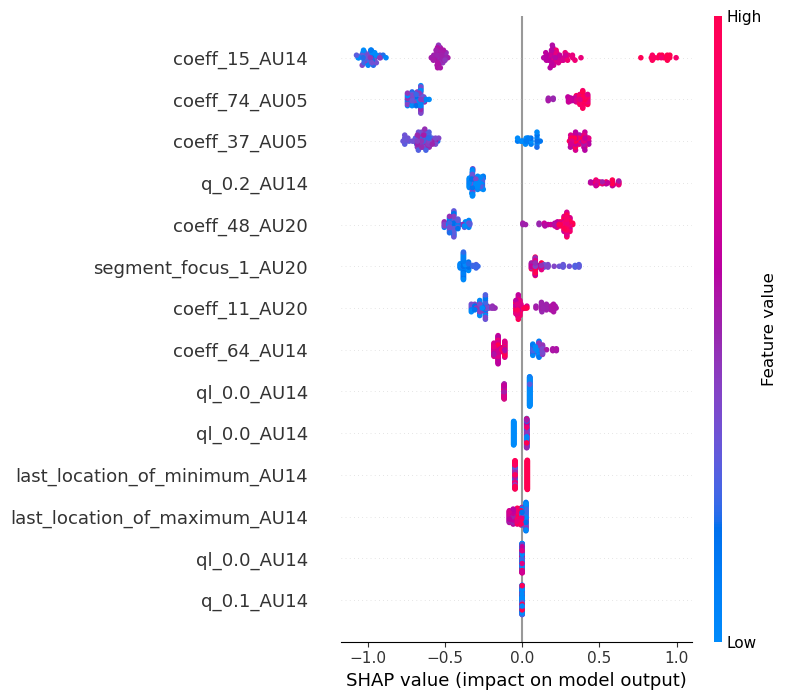

In [512]:
import matplotlib.pyplot as plt

shortened_cols = [col.split('__')[-1] for col in X_selected.columns]  # Keep only the last part of the name

# Re-plot with shorter names
shap.summary_plot(shap_values, X_selected, feature_names=shortened_cols)